# Задание 4. Предсказание года выпуска песни: meansquad

Финальное решение — одна полносвязная сеть с вероятностным выходом и квадратичными признаками.
Ноутбук воспроизводит выбранный **`task4_combined_meansquad.csv`**: public score **80.65531**
по предоставленному скриншоту Kaggle. Это лучший public score среди четырёх отправленных новых вариантов;
он также соответствовал минимальной средней локальной validation MSE. Private score неизвестен.

Здесь оставлена только выбранная конфигурация. Используются исключительно выданные
`task4_data/train_x.csv`, `train_y.csv`, `test_x.csv`. Внешние данные и ансамбли не применяются.
Модель, функция потерь, оптимизатор и метрики написаны на PyTorch; NumPy, pandas и sklearn —
только для предварительной обработки, разбиения и сборки CSV.

Последовательность: проверка данных → meansquad → нейросеть → сравнение AdamW → контрольная оценка →
обучение на всех 14 000 размеченных песнях → **побайтовая проверка совпадения с выбранным submission**.
Ноутбук не зависит от других решений и не изменяет остальные CSV.

In [1]:
import copy
import hashlib
import io
import math
import random
import statistics
import unittest
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
BATCH_SIZE = 256
MAX_EPOCHS = 160
PATIENCE = 25
FINAL_EPOCHS = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.1
SELECTED_CSV = "task4_combined_meansquad.csv"
EXPECTED_SHA256 = "3bf3253cc4c6acdec0cc9ea2a92a34ae2a32c6c94c5f25f01bb9921d43fd7b1d"
torch.set_num_threads(2)


def seed_everything(seed=SEED):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True)


seed_everything()
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.25})
print(f"torch={torch.__version__}, numpy={np.__version__}, pandas={pd.__version__}, "
      f"sklearn={sklearn.__version__}; CPU, 2 threads")
# Проверенный запуск: torch2.14.1 / numpy2.4.6 / pandas3.0.3 / sklearn1.9.0.

torch=2.14.1, numpy=2.4.6, pandas=3.0.3, sklearn=1.9.0; CPU, 2 threads


Matplotlib is building the font cache; this may take a moment.


## 1. Данные

Сопоставляем отдельные метки года по индексам train. Тестовый `id` используется только для CSV,
не входит в признаки и не служит для поиска меток в исходном YearPredictionMSD.
Схема submission `id,year` подтверждена успешной загрузкой выбранного файла на Kaggle.

In [2]:
candidates = [Path("task4_data"), Path("homeworks/task4_data")]
DATA_DIR = next((p for p in candidates if (p / "train_x.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Запустите ноутбук из корня репозитория или из homeworks.")

train_x = pd.read_csv(DATA_DIR / "train_x.csv", index_col=0)
train_y = pd.read_csv(DATA_DIR / "train_y.csv", index_col=0)
test_table = pd.read_csv(DATA_DIR / "test_x.csv")
assert train_x.index.is_unique and train_y.index.is_unique
assert set(train_x.index) == set(train_y.index), "Индексы признаков и меток не совпадают"
train_y = train_y.loc[train_x.index]
assert list(train_y.columns) == ["year"]
assert "id" in test_table and test_table["id"].is_unique
assert not test_table["id"].isna().any()

feature_columns = list(train_x.columns)
assert len(feature_columns) == 90
assert set(test_table.columns) == set(feature_columns) | {"id"}
test_ids = test_table["id"].copy()
test_x = test_table.loc[:, feature_columns].copy()
assert all(pd.api.types.is_numeric_dtype(t) for t in train_x.dtypes)
assert all(pd.api.types.is_numeric_dtype(t) for t in test_x.dtypes)
X = train_x.to_numpy(dtype=np.float64)
X_test = test_x.to_numpy(dtype=np.float64)
y = torch.tensor(train_y["year"].to_numpy(dtype=np.float32))
assert torch.isfinite(y).all() and len(y) == len(X)
assert torch.equal(y, y.round()), "Годы должны быть целыми"
assert not np.isinf(X).any() and not np.isinf(X_test).any()

print(f"Обучение: {X.shape}; тест: {X_test.shape}; целевая переменная: year")
print(f"Пропуски: train={np.isnan(X).sum()}, test={np.isnan(X_test).sum()}")
print(f"Точные дубликаты train: {train_x.duplicated().sum()}")
for name in ("train_x.csv", "train_y.csv", "test_x.csv"):
    print(name, "SHA256:", hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest())

Обучение: (14000, 90); тест: (6000, 90); целевая переменная: year
Пропуски: train=0, test=0
Точные дубликаты train: 0
train_x.csv SHA256: aab2f64a4fdb0fd6af98ed95fedc9a3d9a54506b1f607da725926f654f5bff89
train_y.csv SHA256: 1f72519091e6e08948c430a1db9b181df28095e0cc9f29694570b40daed683bf
test_x.csv SHA256: 54f91d13c6f61fd634bae76bdad109471585a4ce0b308159be16f768134b4046


## 2. Предобработка meansquad

На train оцениваются медианы и StandardScaler для 90 признаков. После масштабирования явно
переходим к **float32**. Из первых 12 координат, ограниченных диапазоном $[-5,5]$, строим все
произведения $x_i x_j$ для $i\le j$: 12 квадратов и 66 попарных взаимодействий. Их добавление
к исходным 90 координатам даёт **168 признаков**. Второй StandardScaler приводит их к сопоставимым масштабам.
Первые 12 координат — статистики среднего тембра; порядок и смысл остальных ковариаций не угадываются.

Это детерминированное преобразование признаков. Обе нормализации обучаются только на соответствующем
train-разбиении; validation, audit и test используют `transform` без повторного `fit`.

In [3]:
class MeansQuadPreprocessor:
    def __init__(self):
        self.imputer = SimpleImputer(strategy="median", keep_empty_features=True)
        self.scaler = StandardScaler()
        self.expanded_scaler = StandardScaler()

    @staticmethod
    def expand(z):
        means = np.clip(z[:, :12], -5, 5)
        i, j = np.triu_indices(12)
        return np.concatenate([z, means[:, i] * means[:, j]], axis=1)

    def normalized(self, x):
        # float32 ДО произведений обязателен для точного воспроизведения эксперимента.
        imputed = self.imputer.transform(x).copy()
        return self.scaler.transform(imputed).astype(np.float32)

    def fit(self, x):
        imputed = self.imputer.fit_transform(x).copy()
        self.scaler.fit(imputed)
        self.expanded_scaler.fit(self.expand(self.normalized(x)))
        return self

    def transform(self, x):
        result = self.expanded_scaler.transform(self.expand(self.normalized(x))).astype(np.float32)
        assert result.shape[1] == 168 and np.isfinite(result).all()
        return torch.from_numpy(result)


class TargetScaler:
    def __init__(self, target):
        self.mean = float(target.mean())
        self.std = max(float(target.std(unbiased=False)), 1e-6)

    def encode(self, target):
        return (target - self.mean) / self.std


@torch.inference_mode()
def regression_metrics(prediction, target):
    assert prediction.shape == target.shape
    error = prediction.double() - target.double()
    mse = error.square().mean().item()
    return {"mse": mse, "rmse": math.sqrt(mse), "mae": error.abs().mean().item()}

## 3. Одна сеть и функция потерь

Архитектура: **168 → 128 → 128 → 91**. После двух скрытых линейных слоёв — BatchNorm, ReLU и
Dropout с вероятностью 0.55. На выходе — распределение по 91 равномерно расположенной точке между
минимальным и максимальным годом обучающей части. К логитам добавляется логарифм сглаженной
частоты соответствующих годов в train (по 0.5 к каждому счётчику).

Пусть $p_k(x)$ — вероятности, $t_k$ — точки сетки. Прогноз года — $\hat y=\sum_k p_k(x)t_k$.
Мягкая метка $q_k(y)\propto\exp(-(y-t_k)^2/(2\sigma^2))$, где $\sigma=0.6$ года.
Обучаем по $L=\mathrm{MSE}((\hat y-\mu)/s,(y-\mu)/s)+2\,\mathrm{CE}(q,p)$;
$\mu,s$ — среднее и стандартное отклонение цели на train.

Распределение помогает учить связь соседних годов и ограничивает прогноз обучающим диапазоном.
Предсказание не округляется: условное среднее года может быть дробным. Это выход одной модели.

In [4]:
class SongYearNetwork(nn.Module):
    def __init__(self, training_target):
        super().__init__()
        scale = TargetScaler(training_target)
        self.mean, self.std = scale.mean, scale.std
        low, high = float(training_target.min()), float(training_target.max())
        self.register_buffer("support", torch.linspace(low, high, 91))
        self.net = nn.Sequential(
            nn.Linear(168, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.55),
            nn.Linear(128, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.55),
            nn.Linear(128, 1)
        )
        # Сохраняем порядок инициализации исходного эксперимента, включая RNG.
        self.net[-1] = nn.Linear(128, 91)
        nearest = (training_target[:, None] - self.support[None, :]).abs().argmin(1)
        counts = torch.bincount(nearest, minlength=91).float() + 0.5
        self.register_buffer("prior_logits", (counts / counts.sum()).log())

    def forward(self, features):
        raw = self.net(features)
        probabilities = (raw + self.prior_logits).softmax(1)
        normalized_year = ((probabilities * self.support).sum(1) - self.mean) / self.std
        return normalized_year, raw

    def loss(self, normalized_prediction, raw, normalized_target):
        mse = F.mse_loss(normalized_prediction, normalized_target)
        years = normalized_target * self.std + self.mean
        soft_target = (-0.5 * ((years[:, None] - self.support[None, :]) / 0.6).square()).softmax(1)
        log_probability = (raw + self.prior_logits).log_softmax(1)
        cross_entropy = -(soft_target * log_probability).sum(1).mean()
        return mse + 2 * cross_entropy


@torch.inference_mode()
def predict(model, features):
    model.eval()
    normalized = torch.cat([model(batch)[0] for batch in features.split(1024)])
    return normalized * model.std + model.mean

## 4. Собственный AdamW и проверка

Храним экспоненциальные средние градиентов и их квадратов:
$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t$, $v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$.
После коррекции смещения выполняем
$\theta_t=(1-\eta_t\lambda)\theta_{t-1}-\eta_t\hat m_t/(\sqrt{\hat v_t}+\epsilon)$.
Weight decay отделён от моментов. Для bias и параметров BatchNorm decay равен нулю.
`grad=None` пропускает параметр вместе со счётчиком и decay; нулевой градиент является шагом.

Ниже четыре теста и далее парное обучение той же сети встроенным и собственным оптимизатором.
Формулы: [Loshchilov & Hutter](https://arxiv.org/abs/1711.05101),
[PyTorch AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html).

In [5]:
class CustomAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)
        for group in self.param_groups:
            if not math.isfinite(group["lr"]) or group["lr"] < 0:
                raise ValueError("lr должен быть конечным и неотрицательным")
            if not math.isfinite(group["eps"]) or group["eps"] <= 0:
                raise ValueError("eps должен быть конечным и положительным")
            if not math.isfinite(group["weight_decay"]) or group["weight_decay"] < 0:
                raise ValueError("weight_decay должен быть конечным и неотрицательным")
            if len(group["betas"]) != 2 or not all(0 <= b < 1 for b in group["betas"]):
                raise ValueError("betas должны лежать в [0, 1)")

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            beta1, beta2 = group["betas"]
            for parameter in group["params"]:
                grad = parameter.grad
                if grad is None:
                    continue
                if grad.is_sparse or torch.is_complex(parameter):
                    raise RuntimeError("Поддерживаются только плотные вещественные градиенты")
                state = self.state[parameter]
                if not state:
                    state["step"] = 0
                    state["exp_avg"] = torch.zeros_like(parameter)
                    state["exp_avg_sq"] = torch.zeros_like(parameter)
                state["step"] += 1
                m, v = state["exp_avg"], state["exp_avg_sq"]
                m.lerp_(grad, 1 - beta1)
                v.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
                correction1 = 1 - beta1 ** state["step"]
                correction2 = 1 - beta2 ** state["step"]
                denominator = v.sqrt().div_(math.sqrt(correction2)).add_(group["eps"])
                parameter.mul_(1 - group["lr"] * group["weight_decay"])
                parameter.addcdiv_(m, denominator, value=-group["lr"] / correction1)
        return loss

In [6]:
class TestCustomAdamW(unittest.TestCase):
    def test_reference_steps_and_parameter_groups(self):
        generator = torch.Generator().manual_seed(101)
        ours = [nn.Parameter(torch.randn(3, 4, generator=generator, dtype=torch.float64)),
                nn.Parameter(torch.randn(4, generator=generator, dtype=torch.float64))]
        reference = [nn.Parameter(p.detach().clone()) for p in ours]
        def groups(parameters):
            return [{"params": [parameters[0]], "lr": 0.003, "weight_decay": 0.1},
                    {"params": [parameters[1]], "lr": 0.002, "weight_decay": 0.0}]
        custom = CustomAdamW(groups(ours), betas=(0.8, 0.95), eps=1e-6)
        builtin = torch.optim.AdamW(groups(reference), betas=(0.8, 0.95), eps=1e-6,
                                    foreach=False, fused=False)
        for step in range(20):
            for i, (p, q) in enumerate(zip(ours, reference)):
                grad = torch.randn(p.shape, generator=generator, dtype=p.dtype)
                if step % 4 == 0 and i == 1:
                    p.grad = q.grad = None
                else:
                    p.grad = torch.zeros_like(grad) if step == 7 else grad
                    q.grad = p.grad.clone()
            custom.step()
            builtin.step()
            for p, q in zip(ours, reference):
                torch.testing.assert_close(p, q, rtol=1e-11, atol=1e-12)

    def test_none_vs_zero_gradient(self):
        p = nn.Parameter(torch.tensor([2.0], dtype=torch.float64))
        optimizer = CustomAdamW([p], lr=0.1, weight_decay=0.2)
        optimizer.step()
        self.assertEqual(p.item(), 2.0)
        self.assertNotIn(p, optimizer.state)
        p.grad = torch.zeros_like(p)
        optimizer.step()
        self.assertAlmostEqual(p.item(), 1.96)
        self.assertEqual(optimizer.state[p]["step"], 1)

    def test_restore_state(self):
        p = nn.Parameter(torch.tensor([1.0, -2.0], dtype=torch.float64))
        a = CustomAdamW([p])
        p.grad = torch.tensor([0.3, -0.1], dtype=p.dtype)
        a.step()
        q = nn.Parameter(p.detach().clone())
        b = CustomAdamW([q])
        b.load_state_dict(copy.deepcopy(a.state_dict()))
        for _ in range(5):
            p.grad = torch.tensor([-0.2, 0.4], dtype=p.dtype)
            q.grad = p.grad.clone()
            a.step()
            b.step()
        torch.testing.assert_close(p, q, rtol=0, atol=0)

    def test_invalid_settings(self):
        for kwargs in [{"lr": -1}, {"eps": 0}, {"betas": (1, 0.9)}, {"weight_decay": -1}]:
            with self.assertRaises(ValueError):
                CustomAdamW([nn.Parameter(torch.ones(1))], **kwargs)


suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestCustomAdamW)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful()

test_invalid_settings (__main__.TestCustomAdamW.test_invalid_settings) ... ok
test_none_vs_zero_gradient (__main__.TestCustomAdamW.test_none_vs_zero_gradient) ... ok
test_reference_steps_and_parameter_groups (__main__.TestCustomAdamW.test_reference_steps_and_parameter_groups) ... ok
test_restore_state (__main__.TestCustomAdamW.test_restore_state) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.026s

OK


## 5. Обучение выбранной конфигурации

Batch size 256, AdamW с learning rate 0.001 и weight decay 0.1, ограничение нормы градиента 5.
Расписание cosine имеет горизонт 160 эпох и нижний коэффициент 0.1. При финальном обучении
на 30 эпохах этот горизонт не сокращается. Для validation сохраняются веса с минимальной MSE,
ранняя остановка — после 25 эпох без улучшения. Все расчёты выполняются на CPU для воспроизводимости.

In [7]:
def make_loader(features, targets, seed):
    return DataLoader(TensorDataset(features, targets), batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(seed), num_workers=0)


def make_optimizer(model, kind):
    decay, no_decay = [], []
    for parameter in model.parameters():
        (decay if parameter.ndim >= 2 else no_decay).append(parameter)
    groups = [{"params": decay, "weight_decay": WEIGHT_DECAY},
              {"params": no_decay, "weight_decay": 0.0}]
    if kind == "custom":
        return CustomAdamW(groups, lr=LEARNING_RATE)
    if kind == "builtin":
        return torch.optim.AdamW(groups, lr=LEARNING_RATE, foreach=False, fused=False)
    raise ValueError(kind)


def learning_rate(epoch):
    phase = (epoch - 1) / (MAX_EPOCHS - 1)
    return LEARNING_RATE * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * phase)))


def train_epoch(model, loader, optimizer, epoch):
    model.train()
    for group in optimizer.param_groups:
        group["lr"] = learning_rate(epoch)
    loss_sum, grad_sum, size = 0.0, 0.0, 0
    for features, target in loader:
        optimizer.zero_grad(set_to_none=True)
        prediction, raw = model(features)
        loss = model.loss(prediction, raw, target)
        if not torch.isfinite(loss):
            raise RuntimeError("Нефинитная функция потерь")
        loss.backward()
        grad = nn.utils.clip_grad_norm_(model.parameters(), 5.0, error_if_nonfinite=True)
        optimizer.step()
        loss_sum += float(loss.detach()) * len(features)
        grad_sum += float(grad) * len(features)
        size += len(features)
    return loss_sum / size, grad_sum / size


def fit_validation(seed, optimizer_kind="builtin"):
    seed_everything(seed)
    tr, va = make_split(seed)
    pp = MeansQuadPreprocessor().fit(X[tr])
    xt, xv = pp.transform(X[tr]), pp.transform(X[va])
    scaler = TargetScaler(y[tr])
    loader = make_loader(xt, scaler.encode(y[tr]), seed)
    model = SongYearNetwork(y[tr])
    optimizer = make_optimizer(model, optimizer_kind)
    best, best_epoch, best_state, stale = math.inf, 0, None, 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        loss, grad = train_epoch(model, loader, optimizer, epoch)
        metrics = regression_metrics(predict(model, xv), y[va])
        history.append(dict(epoch=epoch, loss=loss, grad_norm=grad, **metrics))
        if metrics["mse"] < best:
            best, best_epoch, stale = metrics["mse"], epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            stale += 1
        if stale >= PATIENCE:
            break
    model.load_state_dict(best_state)
    prediction = predict(model, xv)
    print(f"seed={seed}, optimizer={optimizer_kind}, MSE={best:.6f}, "
          f"RMSE={math.sqrt(best):.6f}, best_epoch={best_epoch}")
    return dict(seed=seed, optimizer=optimizer_kind, model=model, preprocessing=pp,
                train_idx=tr, valid_idx=va, prediction=prediction, best_epoch=best_epoch,
                metrics=regression_metrics(prediction, y[va]), history=history)

## 6. Локальная проверка и сравнение оптимизаторов

Общие development-данные — 11 900 песен, контрольная выборка audit — 2 100. Внутри development
проверяем выбранную конфигурацию на разбиениях с seed 42, 17 и 83: каждый раз 9 800 train и 2 100 validation.
Стратификация по укрупнённым периодам сохраняет редкие старые песни; отдельные годы слишком редки.
Эти разбиения пересекаются и ранее участвовали в выборе конфигурации: их среднее не является независимой CV-оценкой.

Правило исходного train/test-разбиения полного YearPredictionMSD неприменимо к номерам строк этого
поднабора. Здесь нет artist-ID, поэтому отсутствие общих исполнителей между частями не гарантируется.

In [8]:
periods = np.digitize(y.tolist(), bins=[1970, 1980, 1990, 2000, 2005])
indices = np.arange(len(X))
development_idx, audit_idx = train_test_split(indices, test_size=0.15, random_state=42, stratify=periods)


def make_split(seed):
    tr, va = train_test_split(development_idx, test_size=0.15 / 0.85, random_state=seed,
                              stratify=periods[development_idx])
    assert (len(tr), len(va), len(audit_idx)) == (9800, 2100, 2100)
    assert not (set(tr) & set(va) or set(tr) & set(audit_idx) or set(va) & set(audit_idx))
    return tr, va


validation_runs = [fit_validation(seed) for seed in (42, 17, 83)]
mean_mse = statistics.mean(r["metrics"]["mse"] for r in validation_runs)
median_epoch = int(statistics.median(r["best_epoch"] for r in validation_runs))
print(f"Средняя validation MSE: {mean_mse:.6f}; медиана лучших эпох: {median_epoch}")
assert median_epoch == FINAL_EPOCHS, "Изменился результат воспроизведения выбранного эксперимента"

custom_run = fit_validation(42, optimizer_kind="custom")
reference_run = validation_runs[0]
max_prediction_delta = (custom_run["prediction"] - reference_run["prediction"]).abs().max().item()
torch.testing.assert_close(custom_run["prediction"], reference_run["prediction"], rtol=0, atol=1e-4)
print(f"Custom − builtin MSE: {custom_run['metrics']['mse'] - reference_run['metrics']['mse']:+.8f}")
print(f"Максимальная разность прогнозов: {max_prediction_delta:.8f} года")

seed=42, optimizer=builtin, MSE=78.441632, RMSE=8.856728, best_epoch=41
seed=17, optimizer=builtin, MSE=75.290970, RMSE=8.677037, best_epoch=19
seed=83, optimizer=builtin, MSE=81.458766, RMSE=9.025451, best_epoch=30
Средняя validation MSE: 78.397123; медиана лучших эпох: 30
seed=42, optimizer=custom, MSE=78.441632, RMSE=8.856728, best_epoch=41
Custom − builtin MSE: +0.00000000
Максимальная разность прогнозов: 0.00000000 года


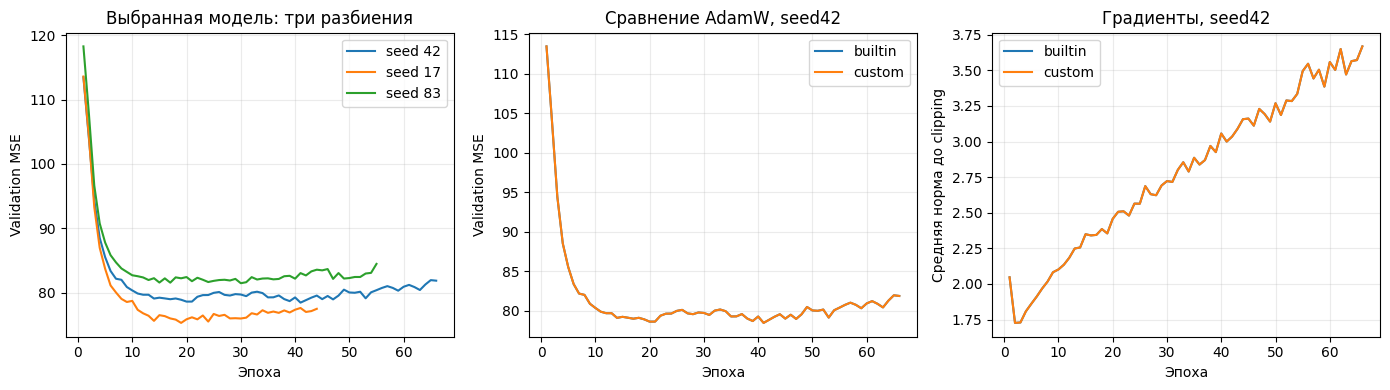

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for run in validation_runs:
    h = run["history"]
    axes[0].plot([r["epoch"] for r in h], [r["mse"] for r in h], label=f"seed {run['seed']}")
for run in [reference_run, custom_run]:
    h = run["history"]
    axes[1].plot([r["epoch"] for r in h], [r["mse"] for r in h], label=run["optimizer"])
    axes[2].plot([r["epoch"] for r in h], [r["grad_norm"] for r in h], label=run["optimizer"])
axes[0].set(xlabel="Эпоха", ylabel="Validation MSE", title="Выбранная модель: три разбиения")
axes[1].set(xlabel="Эпоха", ylabel="Validation MSE", title="Сравнение AdamW, seed42")
axes[2].set(xlabel="Эпоха", ylabel="Средняя норма до clipping", title="Градиенты, seed42")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

## 7. Контрольная оценка выбранной модели

Параметры и число эпох были зафиксированы до открытия новых audit-результатов. Эта контрольная
выборка уже использовалась для оценки исходного решения; ниже воспроизводится диагностика,
а не проводится новый подбор. Результат относится к checkpoint, обученному на 9 800 строках,
а не к финальной модели на 14 000. Заметное различие local audit и public score нормально:
это разные выборки. После этих измерений конфигурация не изменяется.

Audit: {'mse': 83.691337, 'rmse': 9.148297, 'mae': 6.161217}


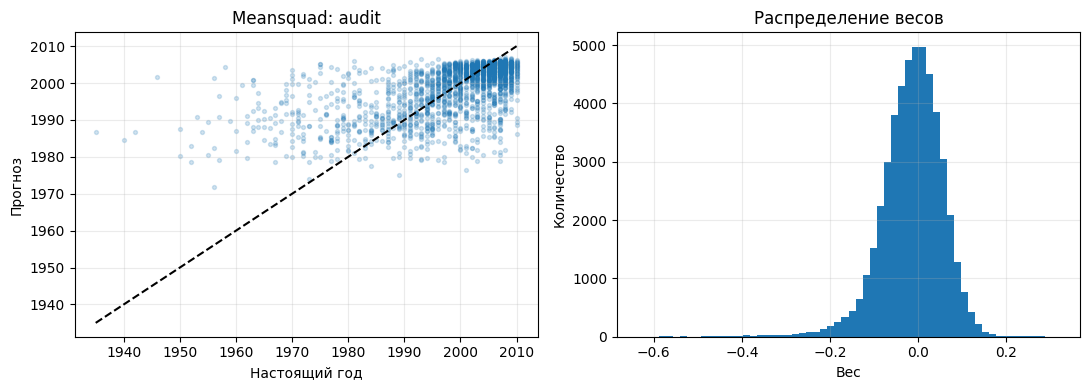

In [10]:
audit_prediction = predict(custom_run["model"], custom_run["preprocessing"].transform(X[audit_idx]))
audit_metrics = regression_metrics(audit_prediction, y[audit_idx])
print("Audit:", {name: round(value, 6) for name, value in audit_metrics.items()})
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y[audit_idx].tolist(), audit_prediction.tolist(), s=8, alpha=0.2)
low, high = float(y[audit_idx].min()), float(y[audit_idx].max())
axes[0].plot([low, high], [low, high], "k--")
axes[0].set(xlabel="Настоящий год", ylabel="Прогноз", title="Meansquad: audit")
weights = torch.cat([p.detach().flatten() for p in custom_run["model"].parameters() if p.ndim >= 2])
axes[1].hist(weights.tolist(), bins=60)
axes[1].set(xlabel="Вес", ylabel="Количество", title="Распределение весов")
fig.tight_layout()
plt.show()

## 8. Финальное обучение и точное воспроизведение submission

Заново обучаем preprocessing на всех 14 000 размеченных объектах и одну сеть с CustomAdamW,
seed42, ровно **30 эпох** (медиана лучших эпох 41/19/30). Расписание остаётся рассчитанным на 160 эпох.
Тест используется только для преобразования и прогноза.

Существующий выбранный CSV только читается и сравнивается побайтово. Если его нет, создаётся
только этот файл; остальные submission не затрагиваются. При несовпадении выполнение останавливается,
чтобы не заменить уже отправленный файл иными прогнозами. Разные версии библиотек или оборудование
могут нарушить побитовое воспроизведение; проверенные версии напечатаны в начале.

In [11]:
seed_everything(42)
final_preprocessing = MeansQuadPreprocessor().fit(X)
full_features = final_preprocessing.transform(X)
final_scaler = TargetScaler(y)
final_loader = make_loader(full_features, final_scaler.encode(y), 42)
final_model = SongYearNetwork(y)
final_optimizer = make_optimizer(final_model, "custom")
for epoch in range(1, FINAL_EPOCHS + 1):
    loss, grad = train_epoch(final_model, final_loader, final_optimizer, epoch)
    if epoch == 1 or epoch % 10 == 0:
        print(f"Final epoch={epoch}, MSE+2CE loss={loss:.6f}")

prediction = predict(final_model, final_preprocessing.transform(X_test))
assert prediction.shape == (6000,) and torch.isfinite(prediction).all()
submission = pd.DataFrame({"id": test_ids.to_numpy(), "year": prediction.numpy()})
csv_bytes = submission.to_csv(index=False, float_format="%.6f").encode("utf-8")
actual_hash = hashlib.sha256(csv_bytes).hexdigest()
assert actual_hash == EXPECTED_SHA256, f"Не воспроизведён выбранный CSV: {actual_hash}"

submission_dir = DATA_DIR / "Submission"
csv_path = submission_dir / SELECTED_CSV
if csv_path.exists():
    assert csv_path.read_bytes() == csv_bytes, "Существующий CSV отличается; файл не изменён"
    print("Существующий CSV совпадает побайтово; запись не потребовалась.")
else:
    submission_dir.mkdir(exist_ok=True)
    csv_path.write_bytes(csv_bytes)
    print("Выбранный CSV создан.")
roundtrip = pd.read_csv(io.BytesIO(csv_bytes))
assert list(roundtrip.columns) == ["id", "year"] and len(roundtrip) == 6000
assert roundtrip["id"].equals(test_ids.reset_index(drop=True))
torch.testing.assert_close(torch.tensor(roundtrip["year"].to_numpy()), prediction.double(), rtol=0, atol=1e-6)
print("Файл:", csv_path)
print("SHA256:", actual_hash)
display(submission.head())

Final epoch=1, MSE+2CE loss=8.128544
Final epoch=10, MSE+2CE loss=7.086723
Final epoch=20, MSE+2CE loss=6.888094
Final epoch=30, MSE+2CE loss=6.767732
Существующий CSV совпадает побайтово; запись не потребовалась.
Файл: task4_data/Submission/task4_combined_meansquad.csv
SHA256: 3bf3253cc4c6acdec0cc9ea2a92a34ae2a32c6c94c5f25f01bb9921d43fd7b1d


,id,year
0,3416,1999.996338
1,18991,2005.013550
2,11105,1997.734131
3,18902,2001.841675
4,18958,2003.330811


## Итог

Выбран **meansquad** с public score **80.65531**, сообщённым пользователем. Средняя validation MSE:
**78.397123**; audit MSE: **83.691337**, RMSE: **9.148297** года, MAE: **6.161217** года.
Собственный AdamW и встроенный AdamW дали одинаковые прогнозы в проверенном CPU-запуске.
Финальный CSV содержит 6 000 прогнозов и воспроизводится побайтово.

Квадратичные признаки не дали устойчивого дополнительного выигрыша на всех локальных проверках.
Выбор этого варианта опирается на лучшую среднюю валидацию и лучший из полученных public scores;
это не доказывает превосходство на private test. Нового подбора по public score здесь нет.

## Источники

- `notebooks/pytorch_intro.ipynb` — семинар: DataLoader, nn.Module, autograd и цикл обучения.
- `homeworks/pytorch.md`, [соревнование Kaggle](https://www.kaggle.com/t/dace4caa40384c86a9879217eaccab42) — условия.
- [UCI YearPredictionMSD](https://archive.ics.uci.edu/dataset/203/yearpredictionmsd) — описание 90 признаков;
  исходный датасет не загружался.
- [Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101),
  [документация AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html) — формулы и эталон тестов.
- [PyTorch: Reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html) — ограничения воспроизводимости.

Функция потерь с мягкой меткой и дополнительными произведениями реализована здесь;
готовые решения соревнования и внешние данные не использовались.